In [29]:
import numpy as np
import matplotlib.pyplot as plt

In [30]:
MAX_ITERACOES = 40
INERCIA = 0.5
COGNITIVO = 0.4
SOCIAL = 0.8
QTD_PARTICULAS = 100


LIMITE = 5.12
DIMENSAO = 5

np.random.seed(42)

In [31]:
def calcula_fitness(posicao):

    ponto_otimo = np.full(DIMENSAO, -1/3)

    return np.linalg.norm(posicao - ponto_otimo)

In [32]:
def calcula_rastrigin(posicao):
    n = len(posicao)

    return 10 * n + np.sum(posicao**2 - 10 * np.cos(2 * np.pi * posicao))

In [33]:
def calcula_objetivo(posicao):

    if np.any(posicao < -LIMITE) or np.any(posicao > LIMITE):
        return float('inf')

    rastrigin = calcula_rastrigin(posicao)

    g = np.sin(2 * np.pi * posicao) + 0.5
    h = np.cos(2 * np.pi * posicao) + 0.5

    penalidade_g = np.sum(np.maximum(g, 0)**2)
    penalidade_h = np.sum(h**2)

    penalidade = 10000 * (penalidade_g + penalidade_h)

    return rastrigin + penalidade

In [34]:
def calcula_velocidade(inercia, cognitivo, social,velocidade, posicao, pbest_posicao, gbest_posicao):
    r1 = np.random.random(size=DIMENSAO)
    r2 = np.random.random(size=DIMENSAO)

    return (inercia * velocidade
        + r1 * cognitivo * (pbest_posicao - posicao)
        + r2 * social * (gbest_posicao - posicao)
    )   

In [35]:
def inicializa_particulas(quantidade):
    lista = []
    for _ in range(quantidade):
        posicao = np.random.uniform(-LIMITE, LIMITE, size=DIMENSAO)

        velocidade = np.random.uniform(-1, 1, size=DIMENSAO)

        fitness = calcula_fitness(posicao)
        objetivo = calcula_objetivo(posicao)

        lista.append({
            'posicao': posicao,
            'fitness': fitness,
            'velocidade': velocidade,
            'pbest_fitness': fitness,
            'pbest_posicao': posicao.copy(),
            'objetivo': objetivo,
            'pbest_objetivo': objetivo,
            })
    return lista

In [36]:
def PSO():
    particulas = inicializa_particulas(QTD_PARTICULAS)
    historico_melhor = []
    historico_media = []
    historico_desvio = []
    

    melhor = min(particulas, key=lambda x: x['pbest_objetivo'])

    gbest_posicao = melhor['pbest_posicao'].copy()
    gbest_objetivo = melhor['pbest_objetivo']

    for interacao in range(MAX_ITERACOES):
        for p in particulas:
            p['velocidade'] = calcula_velocidade(
                INERCIA, COGNITIVO, SOCIAL,
                p['velocidade'],
                p['posicao'],
                p['pbest_posicao'],
                gbest_posicao
            )

            p['posicao'] += p['velocidade']
            p['posicao'] = np.clip(p['posicao'], -LIMITE, LIMITE)

            p['objetivo'] = calcula_objetivo(p['posicao'])

            
            if p['objetivo'] < p['pbest_objetivo']:
                p['pbest_posicao'] = p['posicao'].copy()
                p['pbest_objetivo'] = p['objetivo']

        # OLHAR ISSO DPS --------------
        melhor = min(particulas, key=lambda p: p['pbest_objetivo'])

        if melhor['pbest_objetivo'] < gbest_objetivo:
            gbest_posicao = melhor['pbest_posicao'].copy()
            gbest_objetivo = melhor['pbest_objetivo']
        # OLHAR ISSO DPS --------------

        fitness_populacao = np.array([calcula_fitness(p['posicao']) for p in particulas])

        historico_melhor.append(np.min(fitness_populacao))
        historico_media.append(np.mean(fitness_populacao))
        historico_desvio.append(np.std(fitness_populacao))

    gbest_fitness = calcula_fitness(gbest_posicao)
        
    return gbest_posicao, gbest_fitness, historico_melhor, historico_media, historico_desvio

falta testar e graficos

In [37]:
gbest_posicao, gbest_fitness, historico_melhor, historico_media, historico_desvio = PSO()

print("Melhor posição encontrada:", gbest_posicao)
print("Melhor fitness encontrado:", gbest_fitness)
print("Histórico do melhor fitness:", historico_melhor)
print("Histórico da média:", historico_media)
print("Histórico do desvio padrão:", historico_desvio)

Melhor posição encontrada: [ 2.66675323  0.66676257 -4.3332289  -0.33324445 -1.33323549]
Melhor fitness encontrado: 5.196121637905598
Histórico do melhor fitness: [np.float64(1.8013349991280874), np.float64(2.5629179621914377), np.float64(2.9291630238652604), np.float64(2.5168085031430314), np.float64(2.0814968248756562), np.float64(2.362115188674448), np.float64(2.3392729532011884), np.float64(1.9922172235254465), np.float64(1.6570553016074943), np.float64(2.688367696317478), np.float64(2.4005531431911376), np.float64(2.7348033731496737), np.float64(2.651286664574197), np.float64(3.2546970281375307), np.float64(3.5312947734828417), np.float64(2.9276640652457457), np.float64(3.007146985236645), np.float64(2.893097224787624), np.float64(2.800827331188587), np.float64(2.3572698465921826), np.float64(2.4561942133011407), np.float64(3.2559412580011604), np.float64(3.3460298825437578), np.float64(2.682783088562955), np.float64(2.5235801624080207), np.float64(2.6792858037237566), np.float64(

## Graficos

In [ ]:

# Executa o PSO 20 vezes
resultados = []

for i in range(20):
    resultado = PSO()
    resultados.append(resultado)

    print(f"Execução {i + 1}: Fitness = {resultado[1]:.6f}")


# Extrai a fitness do melhor indivíduo de cada execução
fitness_melhores = np.array([
    resultado[1] for resultado in resultados
])


media_fitness = np.mean(fitness_melhores)
desvio_fitness = np.std(fitness_melhores)

indice_melhor = np.argmin(fitness_melhores)
melhor_posicao = resultados[indice_melhor][0]
melhor_fitness = fitness_melhores[indice_melhor]

print("\n===== RESULTADOS DAS 20 EXECUÇÕES =====")
print("Melhor posição encontrada:", melhor_posicao)
print(f"Melhor fitness: {melhor_fitness:.6f}")
print(f"Média das fitness: {media_fitness:.6f}")
print(f"Desvio padrão das fitness: {desvio_fitness:.6f}")


Execução 1: Fitness = 5.098880
Execução 2: Fitness = 4.123020
Execução 3: Fitness = 5.099147
Execução 4: Fitness = 5.099050
Execução 5: Fitness = 4.690401
Execução 6: Fitness = 7.416284
Execução 7: Fitness = 6.082638
Execução 8: Fitness = 5.000112
Execução 9: Fitness = 5.385092
Execução 10: Fitness = 6.164568
Execução 11: Fitness = 5.196228
Execução 12: Fitness = 1.414211
Execução 13: Fitness = 7.416269
Execução 14: Fitness = 6.782360
Execução 15: Fitness = 3.741740
Execução 16: Fitness = 4.242539
Execução 17: Fitness = 5.477271
Execução 18: Fitness = 4.123168
Execução 19: Fitness = 3.464079
Execução 20: Fitness = 3.316638

===== RESULTADOS DAS 20 EXECUÇÕES =====
Melhor posição encontrada: [-0.33323865 -0.33323726 -1.33323831  0.66675857 -0.33324142]
Melhor fitness: 1.414211
Média das fitness: 4.966685
Desvio padrão das fitness: 1.407926


In [ ]:
    
historico_melhor = resultados[0][2]
historico_media = resultados[0][3]
historico_desvio = resultados[0][4]

geracoes = np.arange(1, MAX_ITERACOES + 1)

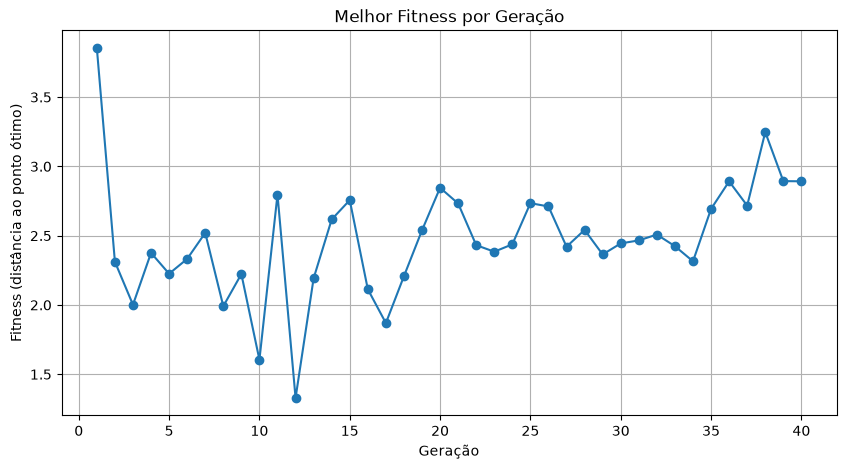

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    geracoes,
    historico_melhor,
    marker='o'
)

plt.title('Melhor Fitness por Geração')
plt.xlabel('Geração')
plt.ylabel('Fitness (distância ao ponto ótimo)')
plt.grid(True)

plt.show()

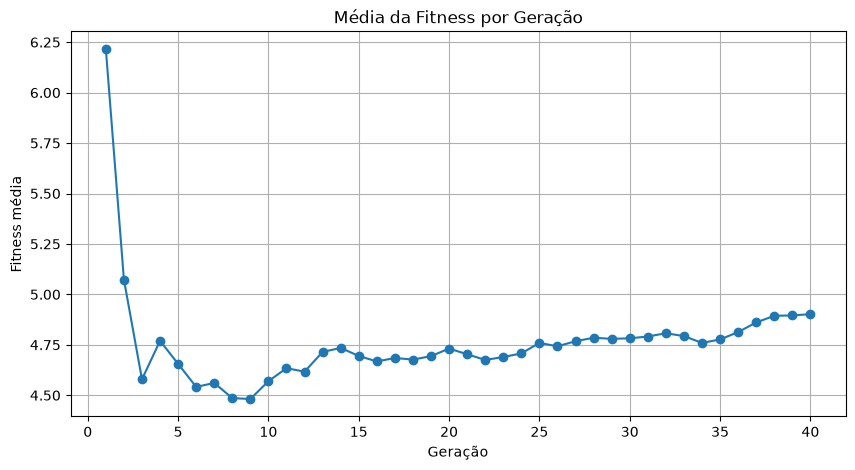

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(
    geracoes,
    historico_media,
    marker='o'
)

plt.title('Média da Fitness por Geração')
plt.xlabel('Geração')
plt.ylabel('Fitness média')
plt.grid(True)

plt.show()

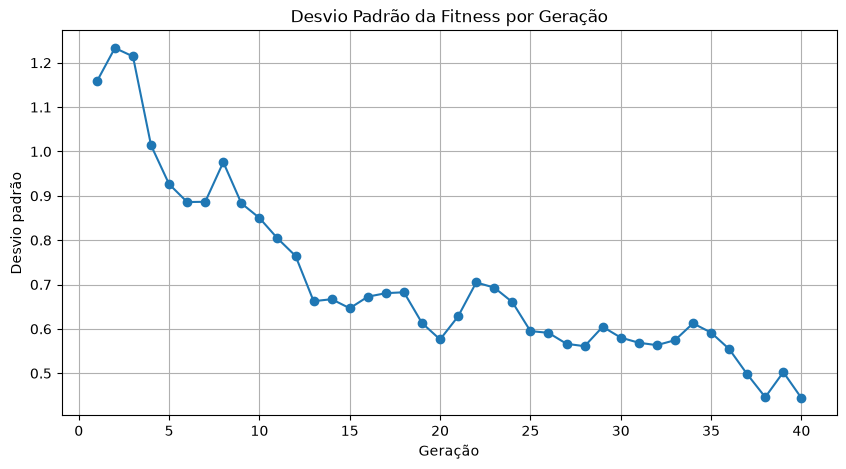

In [42]:
plt.figure(figsize=(10, 5))

plt.plot(
    geracoes,
    historico_desvio,
    marker='o'
)

plt.title('Desvio Padrão da Fitness por Geração')
plt.xlabel('Geração')
plt.ylabel('Desvio padrão')
plt.grid(True)

plt.show()